# ENTRENAMIENTO V11: PINN Pareto-Optimal para Curvas J (N bases)

**Cambios V10 → V11 (cada uno corrige un fallo diagnosticado en la salida de la Célula 12 y en la auditoría del notebook):**

1. **Dataset (Célula 4):** las bases puras ya **no se recortan (`clip`) contra la envolvente**. En V10 el input se recortaba pero la etiqueta no, de modo que c1 > ~4.08 y c4 < ~1.21 producían la *misma* curva con etiquetas distintas (meseta de c1 en ≈4.95 y escalón de c4 en ≈1.2). Además se cubre todo el rango [C_MIN_PURA, 6.0] (antes había un hueco entre ~0.4 y 1.0) y se añaden familias de curvas más diversas que la familia de 1 parámetro α.
2. **Coeficiente máximo único:** `MAX_COEF = 6.0` se define una sola vez (Célula G); se eliminaron los `MAX_COEF = 25.0`, "caja [0,5]" y todos los `globals()`/`locals()` de respaldo.
3. **Configuración única (Célula G):** constantes, rutas de archivos, funciones frontera (Tablas 3 y 6). La Célula 14 ya no usa las fronteras antiguas.
4. **Rigor metodológico (Células 5 y 8):** los escaladores se ajustan **solo con train**; se separa un conjunto de **validación** (early stopping / checkpoint) distinto del **test**.
5. **Persistencia coherente (Células 8 y 14):** el modelo y los escaladores (con `OFFSET_LOG`) se guardan con los nombres que la Célula 14 espera. Se eliminó el relleno silencioso de features.
6. **Bases (Células 0 y 2):** el evolutivo es opcional y ya no sobrescribe el Excel; la Célula 2 es la única que lo escribe y va antes de la 1.
7. **Evaluación (Células 8b–13):** una sola función de evaluación; métricas por familia; sin variables de respaldo inexistentes.


## Célula G — Configuración global (ejecutar SIEMPRE primero)

In [1]:
# ==============================================================================
# CÉLULA G: CONFIGURACIÓN GLOBAL ÚNICA (constantes, archivos y funciones frontera)
# ==============================================================================
"""
Única fuente de verdad del notebook. Ninguna otra célula redefine estas
constantes ni las funciones frontera. EJECUTAR SIEMPRE PRIMERO (también tras
reiniciar el kernel).
"""
import numpy as np

VERSION = "v11"
SEED = 42

# --- Coeficientes: cota superior ÚNICA ---------------------------------------
COEF_MIN = 0.0
MAX_COEF = 6.0

# --- Dominio y malla unificada ------------------------------------------------
X_MIN_DOMINIO = 0.84
X_MAX_DOMINIO = 1.20
N_PUNTOS_MALLA = 999
X_MESH_999 = np.linspace(X_MIN_DOMINIO, X_MAX_DOMINIO, N_PUNTOS_MALLA)

# --- Umbrales de calidad de las bases -----------------------------------------
UMBRAL_COND = 25.0
UMBRAL_R2 = 0.95

# --- Archivos (los usan TODAS las células, incluida la 14) ---------------------
ARCHIVO_BASES = "funciones_base_corregido_v10_intervalo.xlsx"
ARCHIVO_MODELO = f"modelo_rn_curva_j_pinn_{VERSION}.keras"
ARCHIVO_SCALERS = f"scalers_curva_j_pinn_{VERSION}.pkl"

# --- Funciones frontera biofísicas (Tablas 3 y 6) -----------------------------
H_RI_0_T3 = 0.1703   # Tabla 3 (Jóvenes normotensos)
PA_T3 = 5.63         # kPa
H_RI_0_T6 = 0.2197   # Tabla 6 (Hipertensos tratados)
PA_T6 = 5.98         # kPa


def h_ri_cinematica(x, h_ri_0):
    """h/r_i(x) para la condición de incompresibilidad J = 1."""
    return np.sqrt(1.0 + ((1.0 + h_ri_0) ** 2 - 1.0) / (np.maximum(x, 1e-4) ** 2)) - 1.0


def sigma_bar_tabla3(x):
    return 39.87012495 * (np.exp(7.91934038 * (x - 1.0)) - 1.0)


def sigma_bar_tabla6(x):
    return 73.37535695 * (np.exp(10.40342667 * (x - 1.0)) - 1.0)


def y1_tabla3_exacta(x):
    """Frontera Tabla 3 (Normotensos). OJO: NO es siempre la inferior (cruza a Tabla 6 en x≈0.996)."""
    return sigma_bar_tabla3(x) * np.log(1.0 + h_ri_cinematica(x, H_RI_0_T3)) + PA_T3


def y2_tabla6_exacta(x):
    """Frontera Tabla 6 (Hipertensos)."""
    return sigma_bar_tabla6(x) * np.log(1.0 + h_ri_cinematica(x, H_RI_0_T6)) + PA_T6


def envolvente_inferior(x):
    return np.minimum(y1_tabla3_exacta(x), y2_tabla6_exacta(x))


def envolvente_superior(x):
    return np.maximum(y1_tabla3_exacta(x), y2_tabla6_exacta(x))


# Alias de compatibilidad
y1_limite = envolvente_inferior
y2_limite = envolvente_superior

print("✅ Configuración global cargada.")
print(f"   • MAX_COEF = {MAX_COEF} | Malla: {N_PUNTOS_MALLA} pts en [{X_MIN_DOMINIO}, {X_MAX_DOMINIO}]")
print(f"   • Bases: {ARCHIVO_BASES}")
print(f"   • Modelo: {ARCHIVO_MODELO} | Scalers: {ARCHIVO_SCALERS}")

✅ Configuración global cargada.
   • MAX_COEF = 6.0 | Malla: 999 pts en [0.84, 1.2]
   • Bases: funciones_base_corregido_v10_intervalo.xlsx
   • Modelo: modelo_rn_curva_j_pinn_v11.keras | Scalers: scalers_curva_j_pinn_v11.pkl


## Célula 0 — Búsqueda evolutiva de bases (opcional, desactivada por defecto)

In [2]:
# ==============================================================================
# CÉLULA 0 (OPCIONAL): OPTIMIZACIÓN GLOBAL DE LAS BASES CON ALGORITMO EVOLUTIVO
# ==============================================================================
"""
Busca nudos/pendientes/escala de 4 rampas con R2_real alto en todo el dominio
y cond(A) < UMBRAL_COND. NO escribe el Excel: deja el resultado en la variable
PARAMS_BASES_DE. La Célula 2 es la única que construye y exporta las bases
(usa este resultado solo si USAR_RESULTADO_EVOLUTIVO = True allí).
"""
EJECUTAR_EVOLUTIVO = False   # <- poner True para correr la búsqueda (tarda)

if EJECUTAR_EVOLUTIVO:
    import numpy as np
    from scipy.linalg import svd
    from scipy.optimize import lsq_linear, differential_evolution

    x = X_MESH_999
    y_inf = envolvente_inferior(x)
    y_sup = envolvente_superior(x)
    pesos = np.linspace(0.0, 1.0, 11)

    def objetivo(params):
        # params: [k1, k2, k3, m1, m2, m3, m4, escala]
        k1, k2, k3 = params[0], params[1], params[2]
        if not (X_MIN_DOMINIO < k1 < k2 < k3 < X_MAX_DOMINIO):
            return 1e6
        m = params[3:7]
        escala = params[7]

        g1 = m[0] * (x - X_MIN_DOMINIO)
        g2 = m[1] * np.maximum(0.0, x - k1)
        g3 = m[2] * np.maximum(0.0, x - k2)
        g4 = m[3] * np.maximum(0.0, x - k3)
        A_raw = np.column_stack([g1, g2, g3, g4])

        try:
            s = svd(A_raw, compute_uv=False)
            cond = s[0] / s[-1]
        except Exception:
            return 1e6
        if cond >= UMBRAL_COND:
            return cond * 10.0

        A_test = A_raw * escala
        r2_vals = []
        for w in pesos:
            b_test = (1.0 - w) * y_inf + w * y_sup
            res = lsq_linear(A_test, b_test, bounds=(COEF_MIN, MAX_COEF))
            if not res.success:
                return 1e6
            r2 = 1 - np.sum((b_test - A_test @ res.x) ** 2) / np.sum((b_test - b_test.mean()) ** 2)
            r2_vals.append(r2)
        return -min(r2_vals) + (cond / 100.0)

    bounds = [
        (0.85, 0.95), (0.96, 1.05), (1.06, 1.18),          # k1, k2, k3
        (0.5, 2.0), (1.0, 3.0), (2.0, 4.5), (3.0, 6.0),    # m1..m4
        (20.0, 100.0),                                     # escala
    ]

    print("🧬 Ejecutando algoritmo evolutivo (puede tardar)...")
    resultado = differential_evolution(objetivo, bounds, strategy='best1bin',
                                       maxiter=50, popsize=15, seed=SEED, disp=True)
    p = resultado.x
    PARAMS_BASES_DE = dict(knots=list(p[0:3]), pendientes=list(p[3:7]), escala=float(p[7]))

    print("\n" + "=" * 50)
    print("📊 RESULTADO DE LA OPTIMIZACIÓN GLOBAL (guardado en PARAMS_BASES_DE)")
    print("=" * 50)
    for k, v in PARAMS_BASES_DE.items():
        print(f" • {k}: {np.round(v, 4)}")
    print(" ➜ Para usarlo: poner USAR_RESULTADO_EVOLUTIVO = True en la Célula 2.")
else:
    print("ℹ️ Evolutivo omitido (EJECUTAR_EVOLUTIVO = False). La Célula 2 usa los parámetros por defecto.")

ℹ️ Evolutivo omitido (EJECUTAR_EVOLUTIVO = False). La Célula 2 usa los parámetros por defecto.


## Célula 2 — Construcción y exportación de las bases
> Va **antes** de la Célula 1 porque la 1 verifica el Excel que la 2 escribe.

In [3]:
# ==============================================================================
# CÉLULA 2: CONSTRUCCIÓN Y EXPORTACIÓN DE LAS BASES (coeficientes en [0, MAX_COEF])
# ==============================================================================
"""
ÚNICA célula que escribe ARCHIVO_BASES. Escala las bases globalmente para que
con a_i <= MAX_COEF se cubra la magnitud clínica real (el escalado uniforme
preserva cond(A)).
"""
import numpy as np
import pandas as pd
from scipy.linalg import svd

USAR_RESULTADO_EVOLUTIVO = False   # True → usa PARAMS_BASES_DE de la Célula 0

PARAMS_BASES_DEFECTO = dict(
    knots=[0.95, 1.05, 1.1679],
    pendientes=[0.552, 1.2183, 2.0, 6.0],
    escala=100.0,
)

if USAR_RESULTADO_EVOLUTIVO:
    if 'PARAMS_BASES_DE' not in globals():
        raise RuntimeError("PARAMS_BASES_DE no existe: ejecutá la Célula 0 con EJECUTAR_EVOLUTIVO = True.")
    PARAMS_BASES = PARAMS_BASES_DE
else:
    PARAMS_BASES = PARAMS_BASES_DEFECTO


def construir_matriz_bases_escalada(x, knots, pendientes, escala):
    k1, k2, k3 = knots
    m1, m2, m3, m4 = pendientes
    g1 = m1 * (x - X_MIN_DOMINIO)
    g2 = m2 * np.maximum(0.0, x - k1)
    g3 = m3 * np.maximum(0.0, x - k2)
    g4 = m4 * np.maximum(0.0, x - k3)
    return np.column_stack([g1, g2, g3, g4]) * escala


A_opt = construir_matriz_bases_escalada(X_MESH_999, PARAMS_BASES["knots"],
                                        PARAMS_BASES["pendientes"], PARAMS_BASES["escala"])
s_opt = svd(A_opt, compute_uv=False)
cond_opt = s_opt[0] / s_opt[-1]
if cond_opt >= UMBRAL_COND:
    raise ValueError(f"cond(A) = {cond_opt:.2f} >= {UMBRAL_COND}: bases rechazadas.")

y_sup_max = float(envolvente_superior(X_MESH_999).max())
alcance = float((A_opt.max(axis=0) * MAX_COEF).max())

print("\n" + "=" * 54)
print(f"📊 REPORTE DE BASES ESCALADAS PARA CAJA [0, {MAX_COEF:g}]")
print("=" * 54)
print(f" • Nudos [k1, k2, k3] : {PARAMS_BASES['knots']}")
print(f" • Pendientes base    : {PARAMS_BASES['pendientes']}")
print(f" • Factor de escala   : {PARAMS_BASES['escala']}")
print(f" • cond(A) resultante : {cond_opt:.4f}")
print(f" • Máx. por base (x={X_MAX_DOMINIO}) con c=1: {np.round(A_opt[-1], 2)}")
print(f" • y_sup máximo = {y_sup_max:.1f} kPa | alcance máx. con c<={MAX_COEF:g} = {alcance:.1f} kPa")
print("=" * 54)

pd.DataFrame(np.column_stack([X_MESH_999, A_opt])).to_excel(ARCHIVO_BASES, header=False, index=False)
print(f"💾 Archivo guardado con éxito en '{ARCHIVO_BASES}'.")


📊 REPORTE DE BASES ESCALADAS PARA CAJA [0, 6]
 • Nudos [k1, k2, k3] : [0.95, 1.05, 1.1679]
 • Pendientes base    : [0.552, 1.2183, 2.0, 6.0]
 • Factor de escala   : 100.0
 • cond(A) resultante : 13.9013
 • Máx. por base (x=1.2) con c=1: [19.87 30.46 30.   19.26]
 • y_sup máximo = 81.0 kPa | alcance máx. con c<=6 = 182.7 kPa
💾 Archivo guardado con éxito en 'funciones_base_corregido_v10_intervalo.xlsx'.


## Célula 1 — Verificación de R² y cond(A) de las bases

In [4]:
# ==============================================================================
# CÉLULA 1: VERIFICACIÓN FINAL DE R2_REAL Y R2_RELAJADO
# ==============================================================================
"""
Lee las bases desde el Excel y evalúa R2 real (caja [0, MAX_COEF]) y relajado
frente a las envolventes clínicas.
"""
import os
import numpy as np
import pandas as pd
from scipy.linalg import svd
from scipy.optimize import lsq_linear

if not os.path.exists(ARCHIVO_BASES):
    raise FileNotFoundError(f"No se encuentra '{ARCHIVO_BASES}'. Ejecutá antes la Célula 2.")

arr = pd.read_excel(ARCHIVO_BASES, header=None).to_numpy(float)
x, A = arr[:, 0], arr[:, 1:]
n_bases = A.shape[1]
print(f"📊 Malla leída: {len(x)} puntos en [{x[0]:.2f}, {x[-1]:.2f}] con {n_bases} bases activas.")

U, s, _ = svd(A, full_matrices=False)
cond_A = s[0] / s[-1]
estado = "OK" if cond_A < UMBRAL_COND else "FUERA DE UMBRAL"
print(f"   • cond(A) = {cond_A:.2f} (umbral {UMBRAL_COND}) → {estado}\n")

Ue = U[:, s > 1e-10 * s[0]]


def r2_relajado(b):
    resid = b - Ue @ (Ue.T @ b)
    return 1 - np.sum(resid ** 2) / np.sum((b - b.mean()) ** 2)


y_inf = envolvente_inferior(x)
y_sup = envolvente_superior(x)
pesos = np.linspace(0.0, 1.0, 11)
r2_boxes = []

print(f"{'Ponderación (w)':<15} {'R2_relajado':<14} {f'R2_real (caja [0,{MAX_COEF:g}])':<22}")
print("-" * 54)
for w in pesos:
    b_test = (1.0 - w) * y_inf + w * y_sup
    r2_rel = r2_relajado(b_test)
    sol = lsq_linear(A, b_test, bounds=(COEF_MIN, MAX_COEF))
    r2_box = 1 - np.sum((b_test - A @ sol.x) ** 2) / np.sum((b_test - b_test.mean()) ** 2)
    r2_boxes.append(r2_box)
    print(f"{w:15.2f} {r2_rel:14.4f} {r2_box:22.4f}")

r2_boxes_arr = np.array(r2_boxes)
print(f"\n📈 Promedio de R2_real: {r2_boxes_arr.mean():.4f} | mínimo: {r2_boxes_arr.min():.4f} "
      f"(umbral {UMBRAL_R2}) → {'OK' if r2_boxes_arr.min() >= UMBRAL_R2 else 'BAJO UMBRAL'}")

pd.DataFrame({"peso_envolvente": pesos, "R2_real": r2_boxes}).to_csv(
    f"verificacion_cota_svd_{VERSION}_intervalo.csv", index=False)
print(f"💾 Archivo 'verificacion_cota_svd_{VERSION}_intervalo.csv' guardado.")

📊 Malla leída: 999 puntos en [0.84, 1.20] con 4 bases activas.
   • cond(A) = 13.90 (umbral 25.0) → OK

Ponderación (w) R2_relajado    R2_real (caja [0,6])  
------------------------------------------------------
           0.00         0.8839                 0.8648
           0.10         0.9250                 0.9151
           0.20         0.9518                 0.9471
           0.30         0.9692                 0.9674
           0.40         0.9805                 0.9800
           0.50         0.9877                 0.9876
           0.60         0.9921                 0.9921
           0.70         0.9948                 0.9948
           0.80         0.9963                 0.9963
           0.90         0.9969                 0.9969
           1.00         0.9970                 0.9970

📈 Promedio de R2_real: 0.9672 | mínimo: 0.8648 (umbral 0.95) → BAJO UMBRAL
💾 Archivo 'verificacion_cota_svd_v11_intervalo.csv' guardado.


## Célula 3 — Librerías, entorno TensorFlow y transformación logarítmica

In [5]:
# ==============================================================================
# CÉLULA 3: LIBRERÍAS, ENTORNO TENSORFLOW Y TRANSFORMACIÓN LOGARÍTMICA
# ==============================================================================
import os
# Variables de entorno ANTES de importar TensorFlow (si no, no tienen efecto)
os.environ['PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION'] = 'python'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import pickle
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import lsq_linear
from scipy.stats import norm
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

import tensorflow as tf

warnings.filterwarnings('ignore')

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(f"Aviso GPU: {e}")

np.random.seed(SEED)
tf.random.set_seed(SEED)
RNG = np.random.default_rng(SEED)

# ------------------------------------------------------------------------------
# PROTECCIÓN DE LA TRANSFORMACIÓN LOGARÍTMICA (PREVENCIÓN DE NaNs)
# ------------------------------------------------------------------------------
_y_min_possible = float(min(envolvente_inferior(X_MESH_999).min(),
                            envolvente_superior(X_MESH_999).min()))

# OFFSET seguro: (y + OFFSET_LOG) estrictamente > 0 para toda curva con y >= mínimo de la envolvente
OFFSET_LOG = float(np.abs(_y_min_possible) + 5.0)
EPSILON_LOG = 1e-6


def safe_log_transform(y_data, offset=None):
    """Transformación logarítmica blindada contra NaNs e Infs."""
    if offset is None:
        offset = OFFSET_LOG
    y_safe = np.maximum(np.asarray(y_data) + offset, EPSILON_LOG)
    return np.nan_to_num(np.log(y_safe), nan=0.0, posinf=15.0, neginf=-15.0)


print("✅ Entorno inicializado.")
print(f" Malla unificada: {N_PUNTOS_MALLA} puntos en x ∈ [{X_MIN_DOMINIO}, {X_MAX_DOMINIO}]")
print(f"🛡️ OFFSET_LOG = {OFFSET_LOG:.4f} (mínimo de la envolvente: {_y_min_possible:.4f} kPa)")

✅ Entorno inicializado.
 Malla unificada: 999 puntos en x ∈ [0.84, 1.2]
🛡️ OFFSET_LOG = 14.6474 (mínimo de la envolvente: -9.6474 kPa)


## Célula 4 — Dataset sintético V11 (entrada y etiqueta consistentes)

In [6]:
# ==============================================================================
# CÉLULA 4: DATASET SINTÉTICO V11 (ENTRADA Y ETIQUETA SIEMPRE CONSISTENTES)
# ==============================================================================
"""
Regla de oro V11: la etiqueta c nunca se calcula sobre una curva distinta de la
que ve la red. No hay NINGÚN clip de las curvas contra la envolvente.

Familias (vector 'familia'):
  0) PURAS      : una sola base activa, c ~ U(C_MIN_PURA, MAX_COEF). Etiqueta exacta.
  1) COMBINADAS : 2..N bases activas con c ~ U(0, MAX_COEF), reescaladas si la curva
                  supera Y_TECHO_KPA. Ceros exactos en las demás. Etiqueta exacta.
  2) ENVOLVENTE : curva dentro de la envolvente biofísica con alpha(x) suave y
                  aleatorio (no solo un alpha constante). Etiqueta = lsq_linear
                  acotado sobre ESA misma curva (óptimo real).
"""
import os
import numpy as np
import pandas as pd
from scipy.optimize import lsq_linear

# --- Parámetros del dataset ---------------------------------------------------
N_SAMPLES = 30000
FRAC_PURAS = 0.30
FRAC_COMBINADAS = 0.30
FRAC_ENVOLVENTE = 1.0 - FRAC_PURAS - FRAC_COMBINADAS
C_MIN_PURA = 0.05          # evita curvas puras idénticamente nulas
Y_TECHO_KPA = 200.0        # techo de amplitud de las curvas combinadas
RUIDO_REL_PURAS = 0.005
RUIDO_REL_ENVOLVENTE = 0.01
ALPHA_MIN, ALPHA_MAX = -0.05, 1.05   # un poco más allá de las fronteras (robustez en los bordes)
SEED_DATASET = 2026
FAMILIAS = {0: "pura", 1: "combinada", 2: "envolvente"}

rng_ds = np.random.default_rng(SEED_DATASET)
print(f"⚙️ Generando dataset V11: {N_SAMPLES} curvas "
      f"({FRAC_PURAS:.0%} puras / {FRAC_COMBINADAS:.0%} combinadas / {FRAC_ENVOLVENTE:.0%} envolvente)...")

# --- 1. Carga de la matriz de bases (dinámica en N) ----------------------------
if not os.path.exists(ARCHIVO_BASES):
    raise FileNotFoundError(f"No se encontró '{ARCHIVO_BASES}'. Ejecutá la Célula 2.")

df_base = pd.read_excel(ARCHIVO_BASES, header=None)
x_base_file = df_base.iloc[:, 0].values.astype(np.float64)
A_base_full = df_base.iloc[:, 1:].values.astype(np.float64)
n_bases = A_base_full.shape[1]

if len(x_base_file) != N_PUNTOS_MALLA or not np.allclose(x_base_file, X_MESH_999):
    A_base = np.column_stack([np.interp(X_MESH_999, x_base_file, A_base_full[:, j])
                              for j in range(n_bases)])
else:
    A_base = A_base_full.copy()
print(f"📂 Bases cargadas: {n_bases} bases en {N_PUNTOS_MALLA} puntos.")

cota_inferior = envolvente_inferior(X_MESH_999)
cota_superior = envolvente_superior(X_MESH_999)

n_puras = int(round(FRAC_PURAS * N_SAMPLES))
n_comb = int(round(FRAC_COMBINADAS * N_SAMPLES))
n_env = N_SAMPLES - n_puras - n_comb

Y_raw = np.zeros((N_SAMPLES, N_PUNTOS_MALLA), dtype=np.float64)
C_targets = np.zeros((N_SAMPLES, n_bases), dtype=np.float64)
familia = np.zeros(N_SAMPLES, dtype=np.int8)

# --- A) PURAS (balanceadas entre bases, rango completo de c) -------------------
sl = slice(0, n_puras)
base_idx = rng_ds.permutation(np.arange(n_puras) % n_bases)
C_p = np.zeros((n_puras, n_bases))
C_p[np.arange(n_puras), base_idx] = rng_ds.uniform(C_MIN_PURA, MAX_COEF, size=n_puras)
Y_p = C_p @ A_base.T
Y_p = Y_p + rng_ds.normal(0.0, RUIDO_REL_PURAS, size=Y_p.shape) * np.abs(Y_p)
Y_raw[sl], C_targets[sl], familia[sl] = Y_p, C_p, 0

# --- B) COMBINADAS (soporte disperso aleatorio, etiqueta exacta) ---------------
sl = slice(n_puras, n_puras + n_comb)
C_c = np.zeros((n_comb, n_bases))
for i in range(n_comb):
    k = rng_ds.integers(2, n_bases + 1)                      # nº de bases activas (2..N)
    act = rng_ds.choice(n_bases, size=k, replace=False)
    C_c[i, act] = rng_ds.uniform(0.0, MAX_COEF, size=k)
Y_c = C_c @ A_base.T
y_max_c = Y_c.max(axis=1, keepdims=True)
factor = np.minimum(1.0, Y_TECHO_KPA / np.maximum(y_max_c, 1e-9))   # reescala c (sigue <= MAX_COEF)
C_c = C_c * factor
Y_c = C_c @ A_base.T
Y_c = Y_c + rng_ds.normal(0.0, RUIDO_REL_PURAS, size=Y_c.shape) * np.abs(Y_c)
Y_raw[sl], C_targets[sl], familia[sl] = Y_c, C_c, 1

# --- C) ENVOLVENTE con alpha(x) suave y aleatorio, etiqueta = óptimo acotado --------
sl = slice(n_puras + n_comb, N_SAMPLES)
t = (X_MESH_999 - X_MIN_DOMINIO) / (X_MAX_DOMINIO - X_MIN_DOMINIO)
Y_e = np.zeros((n_env, N_PUNTOS_MALLA))
C_e = np.zeros((n_env, n_bases))
for i in range(n_env):
    alpha = rng_ds.uniform(ALPHA_MIN, ALPHA_MAX)
    for kk in (1, 2, 3):
        alpha = alpha + rng_ds.normal(0.0, 0.10 / kk) * np.cos(kk * np.pi * t)
    alpha = np.clip(alpha, ALPHA_MIN, ALPHA_MAX)
    y = cota_inferior + alpha * (cota_superior - cota_inferior)
    y = y + rng_ds.normal(0.0, RUIDO_REL_ENVOLVENTE, size=N_PUNTOS_MALLA) * np.abs(y)
    Y_e[i] = y
    C_e[i] = lsq_linear(A_base, y, bounds=(COEF_MIN, MAX_COEF)).x   # misma curva que ve la red
Y_raw[sl], C_targets[sl], familia[sl] = Y_e, C_e, 2

# Alias de compatibilidad
X_curvas = Y_raw
Y_coef = C_targets

# --- 2. Transformación logarítmica de las entradas -----------------------------
X_log = safe_log_transform(Y_raw, offset=OFFSET_LOG)

# --- 3. Chequeos de integridad y consistencia entrada↔etiqueta -----------------
assert np.isfinite(X_log).all() and np.isfinite(C_targets).all(), "NaN/Inf en el dataset"
assert C_targets.min() >= COEF_MIN - 1e-9 and C_targets.max() <= MAX_COEF + 1e-9, \
    f"Etiquetas fuera de [0, {MAX_COEF}]"

print("\n✅ Dataset V11 generado:")
print(f"   • X_log: {X_log.shape} | C_targets: {C_targets.shape}")
for f, nombre in FAMILIAS.items():
    m = familia == f
    fuera = np.mean((Y_raw[m] < cota_inferior - 1e-9) | (Y_raw[m] > cota_superior + 1e-9))
    print(f"   • {nombre:<11}: {m.sum():>6} curvas | fracción de puntos fuera de la envolvente: {fuera:6.1%}")

print("\n📏 Cobertura de coeficientes (percentiles 5/50/95 y % de muestras con c > 0.7·MAX_COEF):")
for j in range(n_bases):
    p5, p50, p95 = np.percentile(C_targets[:, j], [5, 50, 95])
    print(f"   c{j+1}: p5={p5:5.2f}  p50={p50:5.2f}  p95={p95:5.2f}  | c>{0.7*MAX_COEF:.1f}: {np.mean(C_targets[:, j] > 0.7*MAX_COEF):6.1%}")

print("\n🔍 Consistencia entrada↔etiqueta (re-resolviendo lsq_linear sobre 200 curvas por familia):")
for f, nombre in FAMILIAS.items():
    idx = np.where(familia == f)[0]
    idx = rng_ds.choice(idx, size=min(200, len(idx)), replace=False)
    dif = np.array([np.abs(lsq_linear(A_base, Y_raw[i], bounds=(COEF_MIN, MAX_COEF)).x - C_targets[i]).max()
                    for i in idx])
    print(f"   • {nombre:<11}: |Δc| máx. medio = {dif.mean():.4f} | peor = {dif.max():.4f}")

⚙️ Generando dataset V11: 30000 curvas (30% puras / 30% combinadas / 40% envolvente)...
📂 Bases cargadas: 4 bases en 999 puntos.

✅ Dataset V11 generado:
   • X_log: (30000, 999) | C_targets: (30000, 4)
   • pura       :   9000 curvas | fracción de puntos fuera de la envolvente:  68.6%
   • combinada  :   9000 curvas | fracción de puntos fuera de la envolvente:  87.6%
   • envolvente :  12000 curvas | fracción de puntos fuera de la envolvente:  12.3%

📏 Cobertura de coeficientes (percentiles 5/50/95 y % de muestras con c > 0.7·MAX_COEF):
   c1: p5= 0.00  p50= 0.00  p95= 4.14  | c>4.2:   4.7%
   c2: p5= 0.00  p50= 0.73  p95= 3.90  | c>4.2:   3.9%
   c3: p5= 0.00  p50= 0.50  p95= 3.95  | c>4.2:   4.0%
   c4: p5= 0.00  p50= 0.42  p95= 4.23  | c>4.2:   5.1%

🔍 Consistencia entrada↔etiqueta (re-resolviendo lsq_linear sobre 200 curvas por familia):
   • pura       : |Δc| máx. medio = 0.0025 | peor = 0.0208
   • combinada  : |Δc| máx. medio = 0.0073 | peor = 0.0243
   • envolvente : |Δc| máx.

## Célula 5 — Partición train/val/test y normalización sin fuga

In [7]:
# ==============================================================================
# CÉLULA 5: PARTICIÓN TRAIN / VAL / TEST Y NORMALIZACIÓN (SIN FUGA DE INFORMACIÓN)
# ==============================================================================
"""
Los escaladores se ajustan SOLO con train. La validación (early stopping y
checkpoint) es distinta del test, que queda intacto para la evaluación final.
La partición es estratificada por familia de curva.
"""
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

idx_all = np.arange(len(X_log))
idx_trval, idx_test = train_test_split(
    idx_all, test_size=0.20, random_state=SEED, stratify=familia)
idx_train, idx_val = train_test_split(
    idx_trval, test_size=0.125, random_state=SEED, stratify=familia[idx_trval])   # 0.125·0.8 = 10 %

sx = StandardScaler().fit(X_log[idx_train])      # entradas
sy = StandardScaler().fit(Y_coef[idx_train])     # salidas (coeficientes)

X_train, X_val, X_test = (sx.transform(X_log[i]) for i in (idx_train, idx_val, idx_test))
y_train, y_val, y_test = (sy.transform(Y_coef[i]) for i in (idx_train, idx_val, idx_test))
fam_train, fam_val, fam_test = familia[idx_train], familia[idx_val], familia[idx_test]

print("✅ Datos normalizados y divididos (escaladores ajustados solo con train):")
print(f"   • Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}")
print(f"   • X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"   • sy.mean_  : {np.round(sy.mean_, 4)}")
print(f"   • sy.scale_ : {np.round(sy.scale_, 4)}")

✅ Datos normalizados y divididos (escaladores ajustados solo con train):
   • Train: 21000 | Val: 3000 | Test: 6000
   • X_train shape: (21000, 999) | y_train shape: (21000, 4)
   • sy.mean_  : [0.8047 1.0401 0.9944 0.9334]
   • sy.scale_ : [1.4071 1.2583 1.3068 1.3567]


## Célula 6 — Pérdida PINN V11 y arquitectura (LayerNormalization)

In [8]:
# ==============================================================================
# CÉLULA 6: PÉRDIDA PINN V11 Y ARQUITECTURA (LAYER NORMALIZATION)
# ==============================================================================
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, LayerNormalization
from tensorflow.keras.regularizers import l2

# --- 1. PARÁMETROS (derivados de los datos, sin respaldos por globals()) -----------
L2_REGULARIZATION = 1e-5
PESO_COEF, PESO_REC, PESO_CROSSTALK = 1.0, 5.0, 20.0

N_BASES = y_train.shape[1]
N_PUNTOS = X_train.shape[1]
assert A_base.shape == (N_PUNTOS, N_BASES), \
    f"A_base {A_base.shape} no coincide con (N_PUNTOS, N_BASES) = ({N_PUNTOS}, {N_BASES})"

# A en forma (N_BASES, N_PUNTOS) para: coef (batch, N_BASES) @ A -> curva (batch, N_PUNTOS)
A_mat_np = A_base.T.astype(np.float32)
mean_arr = np.asarray(sy.mean_, dtype=np.float32)
scale_arr = np.asarray(sy.scale_, dtype=np.float32)


# --- 2. PÉRDIDA PINN (constantes estáticas de TF) --------------------------------------
def crear_loss_reconstruccion(A_np, mean_np, scale_np,
                              peso_coef=PESO_COEF, peso_rec=PESO_REC, peso_crosstalk=PESO_CROSSTALK):
    A_tf = tf.constant(A_np, dtype=tf.float32)
    mean_tf = tf.constant(mean_np, dtype=tf.float32)
    scale_tf = tf.constant(scale_np, dtype=tf.float32)

    def loss(y_true, y_pred):
        # A. Pérdida paramétrica en espacio normalizado
        loss_coef = tf.reduce_mean(tf.square(y_true - y_pred))

        # B. Desnormalización
        coef_true = y_true * scale_tf + mean_tf
        coef_pred = y_pred * scale_tf + mean_tf

        # C. No negatividad (c_i >= 0)
        coef_pred_clipped = tf.maximum(coef_pred, 0.0)
        coef_true_clipped = tf.maximum(coef_true, 0.0)

        # D. Reconstrucción física
        b_true = tf.matmul(coef_true_clipped, A_tf)
        b_pred = tf.matmul(coef_pred_clipped, A_tf)

        # E. Error de reconstrucción relativo a la amplitud de cada curva
        y_max_safe = tf.maximum(tf.reduce_max(b_true, axis=1, keepdims=True), 1.0)
        loss_rec = tf.reduce_mean(tf.square((b_true - b_pred) / (y_max_safe + 1e-6)))

        # F. Penalización de crosstalk (canales cuya etiqueta es ~0)
        mascara_ceros = tf.cast(tf.less(coef_true_clipped, 1e-4), tf.float32)
        loss_cross = tf.reduce_mean(tf.square(coef_pred_clipped) * mascara_ceros)

        return peso_coef * loss_coef + peso_rec * loss_rec + peso_crosstalk * loss_cross

    return loss


loss_pinn = crear_loss_reconstruccion(A_mat_np, mean_arr, scale_arr)


# --- 3. ARQUITECTURA ----------------------------------------------------------------------
def construir_modelo(input_shape, num_outputs):
    return Sequential([
        Input(shape=(input_shape,)),
        Dense(256, activation='relu', kernel_regularizer=l2(L2_REGULARIZATION)),
        LayerNormalization(),
        Dense(128, activation='relu', kernel_regularizer=l2(L2_REGULARIZATION)),
        LayerNormalization(),
        Dense(64, activation='relu', kernel_regularizer=l2(L2_REGULARIZATION)),
        LayerNormalization(),
        Dense(num_outputs, activation='linear'),
    ])


model = construir_modelo(input_shape=N_PUNTOS, num_outputs=N_BASES)
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0)
model.compile(optimizer=optimizer, loss=loss_pinn, metrics=['mae', 'mse'])

print("✅ Pérdida PINN y modelo construidos:")
print(f"   • Puntos de entrada: {N_PUNTOS} | Coeficientes de salida: {N_BASES}\n")
model.summary()

✅ Pérdida PINN y modelo construidos:
   • Puntos de entrada: 999 | Coeficientes de salida: 4



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       256,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization             │ (None, 256)            │           512 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_1           │ (None, 128)            │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_2           │ (None, 64)             │           128 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 298,308 (1.14 MB)

 Trainable params: 298,308 (1.14 MB)

 Non-trainable params: 0 (0.00 B)

## Célula 7 — Diagnóstico de integridad

In [9]:
# ==============================================================================
# CÉLULA 7: DIAGNÓSTICO DE INTEGRIDAD DE DATOS (EJECUTAR ANTES DE MODEL.FIT)
# ==============================================================================
import numpy as np

print("🔍 VERIFICACIÓN DE INTEGRIDAD DE TENSORES:")
for nombre, arr in [("X_train", X_train), ("y_train", y_train),
                    ("X_val", X_val), ("y_val", y_val),
                    ("X_test", X_test), ("y_test", y_test)]:
    print(f" • {nombre:<8} {str(arr.shape):<14} NaNs: {np.isnan(arr).sum()} | Infs: {np.isinf(arr).sum()}")

print(f" • Scaler X → medias con NaN: {np.isnan(sx.mean_).sum()} | Scaler Y → medias con NaN: {np.isnan(sy.mean_).sum()}")

c_all = sy.inverse_transform(np.vstack([y_train, y_val, y_test]))
print(f" • Etiquetas físicas: min = {c_all.min():.4f} | max = {c_all.max():.4f} (caja [0, {MAX_COEF:g}])")
assert c_all.min() >= -1e-6 and c_all.max() <= MAX_COEF + 1e-6, "Etiquetas fuera de la caja"
print(" ✅ Integridad OK.")

🔍 VERIFICACIÓN DE INTEGRIDAD DE TENSORES:
 • X_train  (21000, 999)   NaNs: 0 | Infs: 0
 • y_train  (21000, 4)     NaNs: 0 | Infs: 0
 • X_val    (3000, 999)    NaNs: 0 | Infs: 0
 • y_val    (3000, 4)      NaNs: 0 | Infs: 0
 • X_test   (6000, 999)    NaNs: 0 | Infs: 0
 • y_test   (6000, 4)      NaNs: 0 | Infs: 0
 • Scaler X → medias con NaN: 0 | Scaler Y → medias con NaN: 0
 • Etiquetas físicas: min = 0.0000 | max = 5.9994 (caja [0, 6])
 ✅ Integridad OK.


## Célula 8 — Entrenamiento y guardado de modelo + escaladores

🚀 Entrenamiento V11 para N = 4 bases (999 pts) | validación ≠ test...
Epoch 1/500
329/329 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.5438 - mae: 0.2991 - mse: 0.2541 - val_loss: 0.1109 - val_mae: 0.1568 - val_mse: 0.0528 - learning_rate: 0.0010
Epoch 2/500
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1329 - mae: 0.1716 - mse: 0.0686 - val_loss: 0.0650 - val_mae: 0.1220 - val_mse: 0.0320 - learning_rate: 0.0010
Epoch 3/500
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.1069 - mae: 0.1452 - mse: 0.0502 - val_loss: 0.2000 - val_mae: 0.2147 - val_mse: 0.0955 - learning_rate: 0.0010
Epoch 4/500
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0968 - mae: 0.1375 - mse: 0.0408 - val_loss: 0.0639 - val_mae: 0.1168 - val_mse: 0.0268 - learning_rate: 0.0010
Epoch 5/500
329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0757 - mae: 0.1176 - mse: 0.0291 - val_loss: 0.0551 - val_mae: 0.1154 - val_mse: 0.0243 - learning_rate: 0.0010
Epoch 6/500
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step -

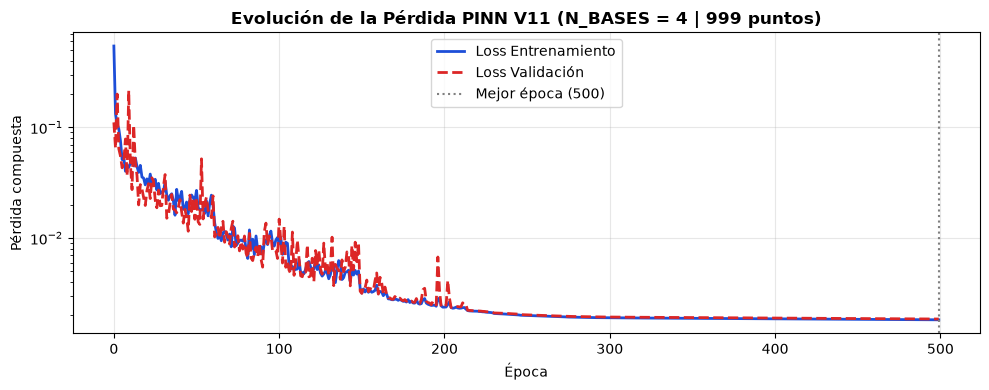

In [10]:
# ==============================================================================
# CÉLULA 8: ENTRENAMIENTO PINN V11 Y GUARDADO DE MODELO + ESCALADORES
# ==============================================================================
import time
import pickle
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, TerminateOnNaN

PATIENCE_EARLY_STOP = 35
EPOCHS = 500
BATCH_SIZE = 64

callbacks = [
    TerminateOnNaN(),
    EarlyStopping(monitor='val_loss', patience=PATIENCE_EARLY_STOP, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=15, min_lr=1e-6, verbose=1),
    ModelCheckpoint(filepath=ARCHIVO_MODELO, monitor='val_loss', save_best_only=True, verbose=0),
]

print(f"🚀 Entrenamiento V11 para N = {N_BASES} bases ({N_PUNTOS} pts) | validación ≠ test...")
t_start = time.time()

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),      # el test NO participa en el entrenamiento ni en la selección
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1,
)

t_elapsed = time.time() - t_start
val_hist = history.history['val_loss']
best_ep = int(np.argmin(val_hist)) + 1
print(f"\n✅ Entrenamiento completado en {t_elapsed/60:.2f} min ({len(val_hist)} épocas ejecutadas).")
print(f"   • Mejor época: {best_ep} | Mejor val_loss: {min(val_hist):.6f}")
print(f"   • MAE de validación en la mejor época: {history.history['val_mae'][best_ep - 1]:.6f}")

# --- Guardado coherente con la Célula 14 -------------------------------------------------
model.save(ARCHIVO_MODELO)
with open(ARCHIVO_SCALERS, "wb") as f:
    pickle.dump({
        "scaler_x": sx,
        "scaler_y": sy,
        "offset_log": OFFSET_LOG,
        "max_coef": MAX_COEF,
        "n_bases": N_BASES,
        "x_mesh": X_MESH_999,
        "version": VERSION,
    }, f)
print(f"💾 Modelo → '{ARCHIVO_MODELO}' | Escaladores + OFFSET_LOG → '{ARCHIVO_SCALERS}'")

plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Loss Entrenamiento', color='#1d4ed8', linewidth=2)
plt.plot(val_hist, label='Loss Validación', color='#dc2626', linewidth=2, linestyle='--')
plt.axvline(best_ep - 1, color='gray', linestyle=':', label=f'Mejor época ({best_ep})')
plt.title(f'Evolución de la Pérdida PINN {VERSION.upper()} (N_BASES = {N_BASES} | {N_PUNTOS} puntos)',
          fontsize=12, fontweight='bold')
plt.xlabel('Época', fontsize=10)
plt.ylabel('Pérdida compuesta', fontsize=10)
plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

## Célula 8b — Evaluación base en test (la reutilizan 9, 12 y 13)

In [11]:
# ==============================================================================
# CÉLULA 8b: EVALUACIÓN BASE SOBRE EL CONJUNTO DE TEST (la usan las Células 9, 12 y 13)
# ==============================================================================
import numpy as np


def evaluar_test():
    """Inferencia sobre test + reconstrucción física. Un único lugar para todo."""
    y_pred_norm = model.predict(X_test, verbose=0)
    coef_rn = np.clip(sy.inverse_transform(y_pred_norm), COEF_MIN, MAX_COEF)
    coef_opt = sy.inverse_transform(y_test)             # etiquetas físicas
    return {
        "coef_rn": coef_rn,                              # (n_test, N_BASES) predicho
        "coef_opt": coef_opt,                            # (n_test, N_BASES) etiqueta
        "b_rn": coef_rn @ A_base.T,                      # curva reconstruida por la PINN
        "b_opt": coef_opt @ A_base.T,                    # curva reconstruida con la etiqueta
        "b_in": Y_raw[idx_test],                         # curva REAL de entrada a la red
        "fam": fam_test,
    }


EVAL = evaluar_test()
print(f"✅ Evaluación base lista: {EVAL['coef_rn'].shape[0]} curvas de test, {EVAL['coef_rn'].shape[1]} coeficientes.")

✅ Evaluación base lista: 6000 curvas de test, 4 coeficientes.


## Célula 9 — Reconstrucción física en test y fronteras analíticas

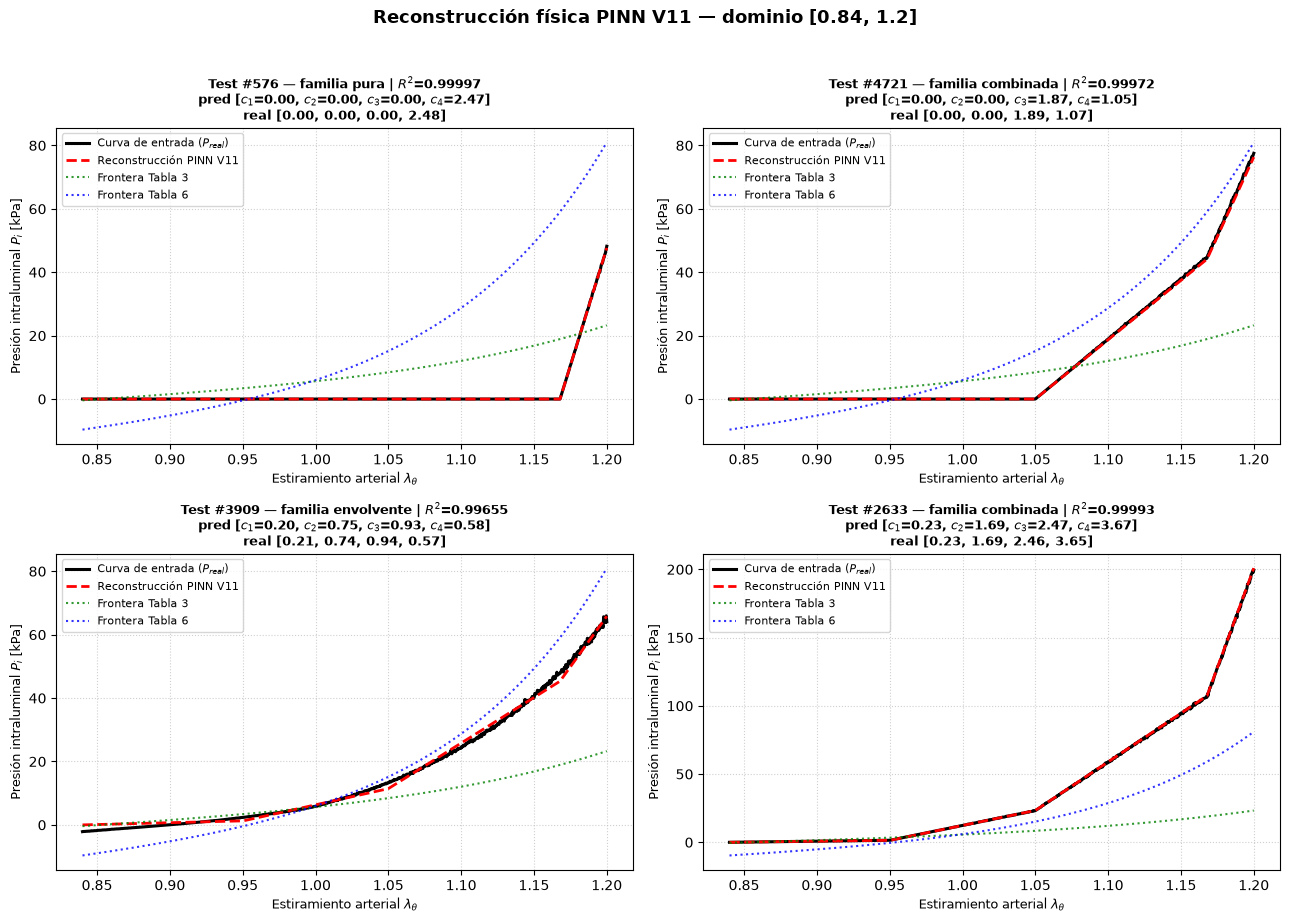


=== EVALUACIÓN DE LAS FRONTERAS ANALÍTICAS (Tabla 3 y Tabla 6) ===
✅ Coeficientes predichos para la frontera Tabla 3: [0.5494, 0.099, 0.0857, 0.0649]
✅ Coeficientes predichos para la frontera Tabla 6: [0.0, 0.8561, 1.203, 0.5576]


In [12]:
# ==============================================================================
# CÉLULA 9: RECONSTRUCCIÓN FÍSICA EN TEST (UNA MUESTRA POR FAMILIA + 1 ALEATORIA)
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

x_mesh = X_MESH_999
y1_full = y1_tabla3_exacta(x_mesh)
y2_full = y2_tabla6_exacta(x_mesh)

rng_plot = np.random.default_rng(SEED)
idx_muestras = [int(rng_plot.choice(np.where(EVAL["fam"] == f)[0])) for f in sorted(FAMILIAS)]
idx_muestras.append(int(rng_plot.integers(0, len(EVAL["fam"]))))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, s in zip(axes.flatten(), idx_muestras):
    b_in, b_rn = EVAL["b_in"][s], EVAL["b_rn"][s]
    c_pred, c_true = EVAL["coef_rn"][s], EVAL["coef_opt"][s]

    ax.plot(x_mesh, b_in, 'k-', lw=2.2, label='Curva de entrada ($P_{real}$)')
    ax.plot(x_mesh, b_rn, 'r--', lw=2.0, label=f'Reconstrucción PINN {VERSION.upper()}')
    ax.plot(x_mesh, y1_full, 'g:', alpha=0.8, lw=1.5, label='Frontera Tabla 3')
    ax.plot(x_mesh, y2_full, 'b:', alpha=0.8, lw=1.5, label='Frontera Tabla 6')

    coef_str = ", ".join(f"$c_{i+1}$={c_pred[i]:.2f}" for i in range(N_BASES))
    true_str = ", ".join(f"{c_true[i]:.2f}" for i in range(N_BASES))
    ax.set_title(f"Test #{s} — familia {FAMILIAS[int(EVAL['fam'][s])]} | $R^2$={r2_score(b_in, b_rn):.5f}\n"
                 f"pred [{coef_str}]\nreal [{true_str}]", fontsize=9, fontweight='bold')
    ax.set_xlabel(r"Estiramiento arterial $\lambda_\theta$", fontsize=9)
    ax.set_ylabel("Presión intraluminal $P_i$ [kPa]", fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper left', fontsize=8)

plt.suptitle(f"Reconstrucción física PINN {VERSION.upper()} — dominio [{X_MIN_DOMINIO}, {X_MAX_DOMINIO}]",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f"reconstruccion_curvas_test_{VERSION}.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# --- Test de inferencia en las fronteras analíticas ---------------------------------------------
print("\n=== EVALUACIÓN DE LAS FRONTERAS ANALÍTICAS (Tabla 3 y Tabla 6) ===")
for nombre, y_fr in [("Tabla 3", y1_full), ("Tabla 6", y2_full)]:
    Xn = sx.transform(safe_log_transform(y_fr).reshape(1, -1))
    c_fr = np.clip(sy.inverse_transform(model.predict(Xn, verbose=0))[0], COEF_MIN, MAX_COEF)
    print(f"✅ Coeficientes predichos para la frontera {nombre}: {[round(float(c), 4) for c in c_fr]}")

## Célula 10 — Fronteras y1 (Tabla 3) / y2 (Tabla 6): PINN vs. óptimo KKT

In [13]:
# ==============================================================================
# CÉLULA 10: FRONTERAS y1(x) [TABLA 3] E y2(x) [TABLA 6] — PINN vs. ÓPTIMO KKT
# ==============================================================================
"""
Nota: Tabla 3 y Tabla 6 se cruzan en x ≈ 0.996, por lo que y1 no es la envolvente
inferior en todo el dominio; se las nombra por su tabla de origen.
La ventana de evaluación es el dominio completo de la malla (ajustable).
"""
import time
import numpy as np
from scipy.optimize import Bounds, minimize, lsq_linear
from sklearn.metrics import mean_squared_error, r2_score

VENTANA_EVAL = (X_MIN_DOMINIO, X_MAX_DOMINIO)
MASK_EVAL = (X_MESH_999 >= VENTANA_EVAL[0]) & (X_MESH_999 <= VENTANA_EVAL[1])
x_eval = X_MESH_999[MASK_EVAL]
A_eval = A_base[MASK_EVAL, :]

limites_kkt = Bounds(COEF_MIN, MAX_COEF)


def _metricas(y_real, y_aprox):
    rmse = float(np.sqrt(mean_squared_error(y_real, y_aprox)))
    rango = float(y_real.max() - y_real.min())
    return {"r2": float(r2_score(y_real, y_aprox)), "rmse": rmse,
            "nrmse": rmse / rango * 100.0 if rango > 0 else 0.0}


def evaluar_frontera(y_full, nombre):
    y_ac = y_full[MASK_EVAL]

    # Óptimo directo bajo KKT (trust-constr) y verificación cruzada con lsq_linear
    t0 = time.time()
    res_kkt = minimize(lambda c: 0.5 * np.sum((A_eval @ c - y_ac) ** 2), np.zeros(N_BASES),
                       jac=lambda c: A_eval.T @ (A_eval @ c - y_ac),
                       method="trust-constr", bounds=limites_kkt,
                       options={"xtol": 1e-12, "gtol": 1e-12})
    t_kkt = time.time() - t0
    coef_opt = res_kkt.x
    coef_lsq = lsq_linear(A_eval, y_ac, bounds=(COEF_MIN, MAX_COEF)).x

    # PINN (recibe la curva completa de 999 puntos)
    Xn = sx.transform(safe_log_transform(y_full).reshape(1, -1))
    coef_pred = np.clip(sy.inverse_transform(model.predict(Xn, verbose=0)).flatten(), COEF_MIN, MAX_COEF)

    b_rn = (A_base @ coef_pred)[MASK_EVAL]
    b_opt = A_eval @ coef_opt
    return {"nombre": nombre, "y": y_ac, "coef_pred": coef_pred, "coef_opt": coef_opt,
            "coef_lsq": coef_lsq, "b_rn": b_rn, "b_opt": b_opt, "t_kkt": t_kkt,
            "m_rn": _metricas(y_ac, b_rn), "m_opt": _metricas(y_ac, b_opt)}


def reportar_frontera(r):
    print("\n" + "=" * 80)
    print(f"EVALUACIÓN EN DOMINIO {VENTANA_EVAL}: {r['nombre']}  (N = {N_BASES})")
    print("=" * 80)
    print(f"Coeficientes óptimos KKT   : {np.round(r['coef_opt'], 4)}   (lsq_linear: {np.round(r['coef_lsq'], 4)})")
    print(f"Coeficientes predichos PINN: {np.round(r['coef_pred'], 4)}")
    print(f"Tiempo KKT: {r['t_kkt']*1000:.1f} ms")
    for etiqueta, m in [("PINN", r["m_rn"]), ("ÓPTIMO KKT", r["m_opt"])]:
        print("-" * 80)
        print(f"{etiqueta}: R² = {m['r2']:.6f} | RMSE = {m['rmse']:.4f} kPa | NRMSE = {m['nrmse']:.4f}%")
    print("=" * 80)


RES_Y1 = evaluar_frontera(y1_tabla3_exacta(X_MESH_999), "y1(x) [Tabla 3 - Normotensos]")
RES_Y2 = evaluar_frontera(y2_tabla6_exacta(X_MESH_999), "y2(x) [Tabla 6 - Hipertensos]")
reportar_frontera(RES_Y1)
reportar_frontera(RES_Y2)


EVALUACIÓN EN DOMINIO (0.84, 1.2): y1(x) [Tabla 3 - Normotensos]  (N = 4)
Coeficientes óptimos KKT   : [0.5225 0.1637 0.1916 0.1217]   (lsq_linear: [0.5225 0.1637 0.1916 0.1217])
Coeficientes predichos PINN: [0.5494 0.099  0.0857 0.0649]
Tiempo KKT: 346.3 ms
--------------------------------------------------------------------------------
PINN: R² = 0.909797 | RMSE = 1.9576 kPa | NRMSE = 8.2687%
--------------------------------------------------------------------------------
ÓPTIMO KKT: R² = 0.998657 | RMSE = 0.2389 kPa | NRMSE = 1.0090%

EVALUACIÓN EN DOMINIO (0.84, 1.2): y2(x) [Tabla 6 - Hipertensos]  (N = 4)
Coeficientes óptimos KKT   : [0.     1.0328 1.1895 0.7718]   (lsq_linear: [0.     1.0328 1.1895 0.7718])
Coeficientes predichos PINN: [0.     0.8561 1.203  0.5576]
Tiempo KKT: 118.5 ms
--------------------------------------------------------------------------------
PINN: R² = 0.964414 | RMSE = 4.5628 kPa | NRMSE = 5.0341%
---------------------------------------------------------

## Célula 11 — Gráficos de reconstrucción y residuos en y1/y2

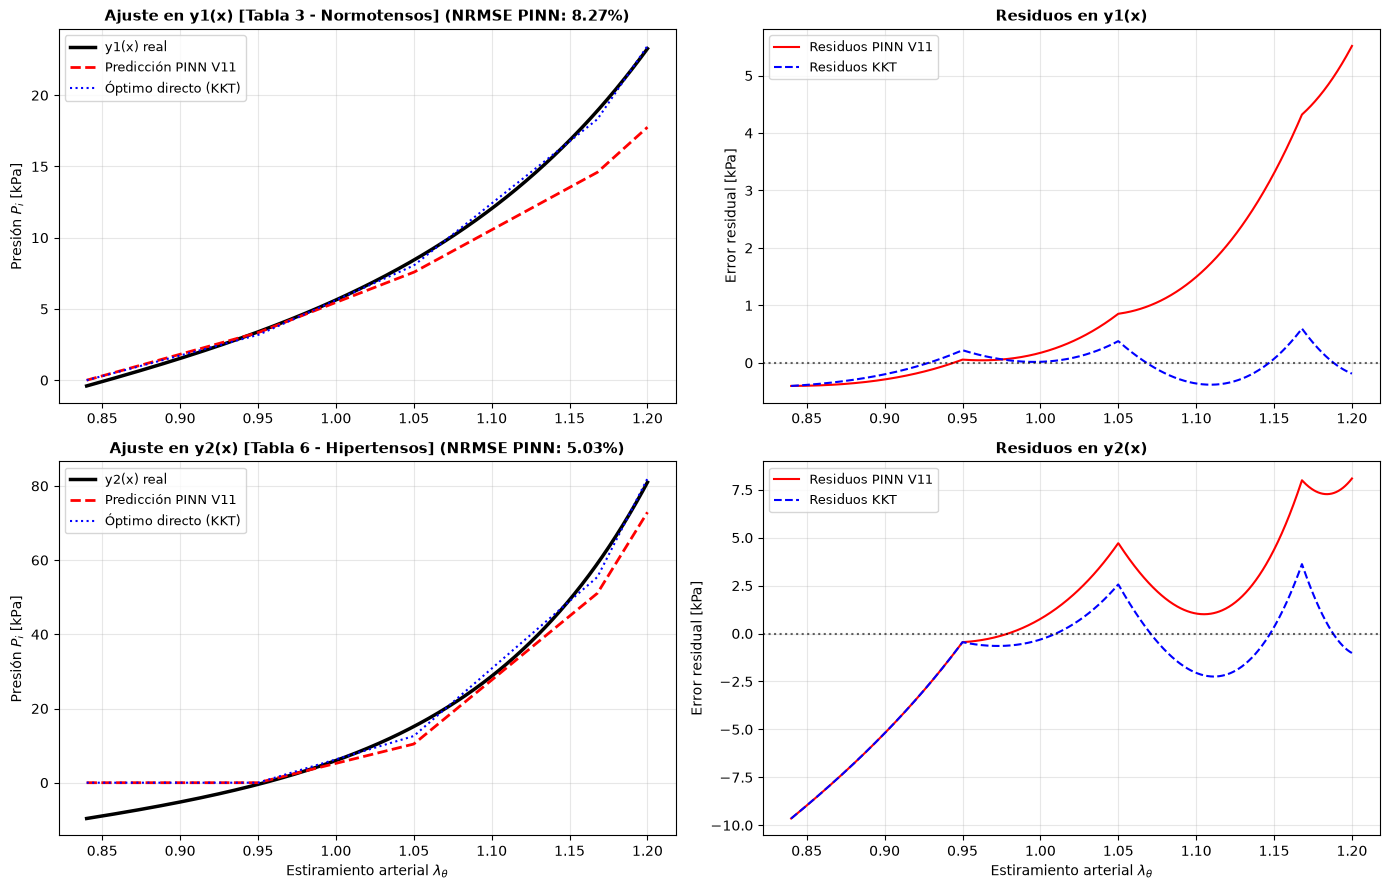

In [14]:
# ==============================================================================
# CÉLULA 11: VISUALIZACIÓN DE RECONSTRUCCIÓN Y RESIDUOS EN y1(x) E y2(x)
# ==============================================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for fila, (res, titulo) in enumerate([(RES_Y1, "y1(x) [Tabla 3 - Normotensos]"),
                                      (RES_Y2, "y2(x) [Tabla 6 - Hipertensos]")]):
    ax_a, ax_r = axes[fila]
    ax_a.plot(x_eval, res["y"], "k-", linewidth=2.5, label=f"{titulo.split(' ')[0]} real")
    ax_a.plot(x_eval, res["b_rn"], "r--", linewidth=2, label=f"Predicción PINN {VERSION.upper()}")
    ax_a.plot(x_eval, res["b_opt"], "b:", linewidth=1.5, label="Óptimo directo (KKT)")
    ax_a.set_ylabel(r"Presión $P_i$ [kPa]", fontsize=10)
    ax_a.set_title(f"Ajuste en {titulo} (NRMSE PINN: {res['m_rn']['nrmse']:.2f}%)", fontsize=11, fontweight="bold")
    ax_a.legend(fontsize=9)
    ax_a.grid(True, alpha=0.3)

    ax_r.plot(x_eval, res["y"] - res["b_rn"], "r-", linewidth=1.5, label=f"Residuos PINN {VERSION.upper()}")
    ax_r.plot(x_eval, res["y"] - res["b_opt"], "b--", linewidth=1.5, label="Residuos KKT")
    ax_r.axhline(0, color="black", linestyle=":", alpha=0.6)
    ax_r.set_ylabel("Error residual [kPa]", fontsize=10)
    ax_r.set_title(f"Residuos en {titulo.split(' ')[0]}", fontsize=11, fontweight="bold")
    ax_r.legend(fontsize=9)
    ax_r.grid(True, alpha=0.3)

for ax in axes[1]:
    ax.set_xlabel(r"Estiramiento arterial $\lambda_\theta$", fontsize=10)

plt.tight_layout()
plt.savefig(f"Grafico_Reconstruccion_Fronteras_y1_y2_{VERSION}.png", dpi=300)
plt.show()
plt.close()

## Célula 12 — Evaluación global en test, regresión 1:1 y residuos

📊 Evaluando la PINN V11 en el conjunto de prueba (Test)...

🎯 PRECISIÓN EN PREDICCIÓN DE COEFICIENTES (N = 4)
Coeficiente  | R² Score        | MAE             | RMSE           
-----------------------------------------------------------------
c1           | 0.999932        | 0.005380        | 0.011499       
c2           | 0.999917        | 0.006276        | 0.011303       
c3           | 0.999902        | 0.006820        | 0.012756       
c4           | 0.999853        | 0.008972        | 0.016472       
-----------------------------------------------------------------
PROMEDIO     | 0.999901        | 0.006862        | 0.013008       

📊 MÉTRICAS GLOBALES DE RECONSTRUCCIÓN FÍSICA (malla 999 puntos)
 • R² medio (curva etiqueta vs PINN) : 0.999846
 • R² medio (curva de ENTRADA vs PINN): 0.986629
 • MAE                                : 0.0949 kPa
 • RMSE                               : 0.2193 kPa
 • NRMSE                              : 0.1097 %

🧬 DESGLOSE POR FAMILIA DE CURVA (MAE de ca

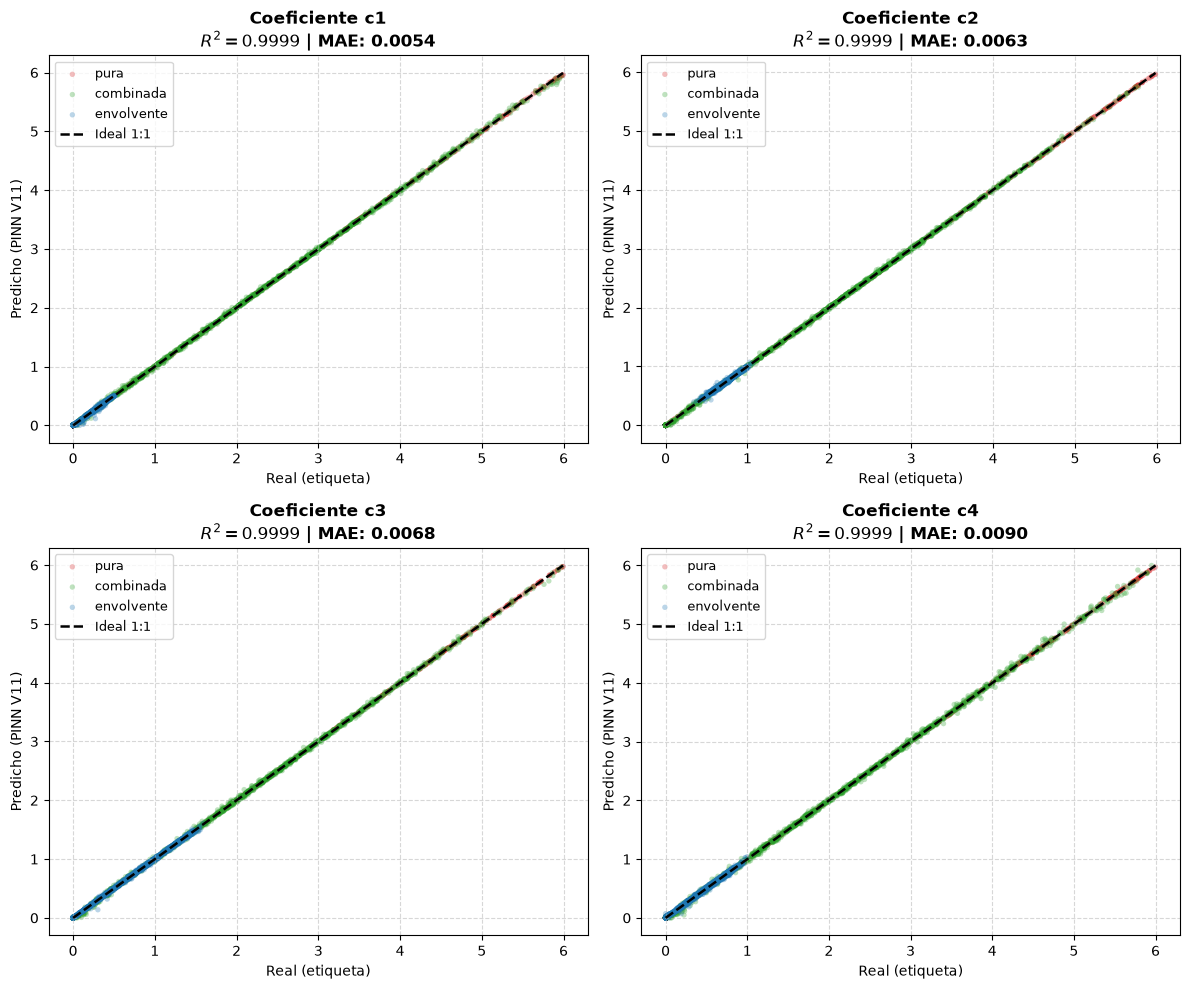

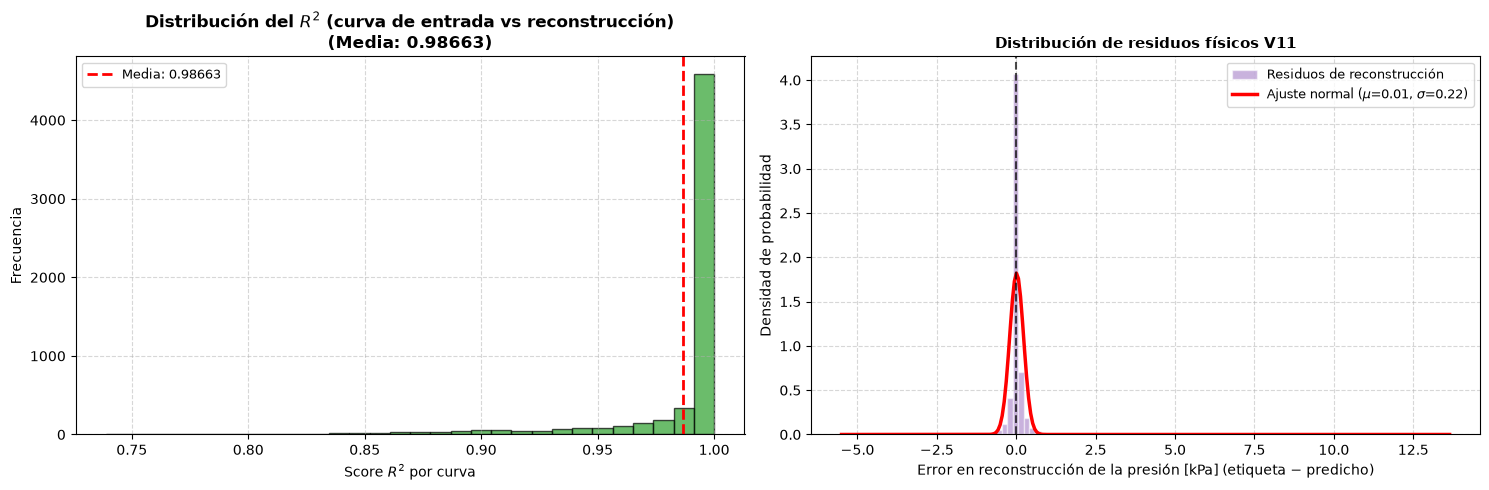

✅ Célula 12 ejecutada correctamente.


In [15]:
# ==============================================================================
# CÉLULA 12: EVALUACIÓN GLOBAL EN TEST, REGRESIÓN 1:1 Y DISTRIBUCIÓN DE RESIDUOS
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print(f"📊 Evaluando la PINN {VERSION.upper()} en el conjunto de prueba (Test)...\n")

coef_rn_test, coef_optimo_test = EVAL["coef_rn"], EVAL["coef_opt"]
b_test_real, b_test_rn, b_test_in = EVAL["b_opt"], EVAL["b_rn"], EVAL["b_in"]
fam_t = EVAL["fam"]
residuos_globales = b_test_real - b_test_rn

# --- Métricas paramétricas y globales ----------------------------------------------------------
N_COEFS = coef_optimo_test.shape[1]
r2_coefs = [r2_score(coef_optimo_test[:, i], coef_rn_test[:, i]) for i in range(N_COEFS)]
mae_coefs = [mean_absolute_error(coef_optimo_test[:, i], coef_rn_test[:, i]) for i in range(N_COEFS)]
rmse_coefs = [np.sqrt(mean_squared_error(coef_optimo_test[:, i], coef_rn_test[:, i])) for i in range(N_COEFS)]

r2_curvas = np.array([r2_score(b_test_real[i], b_test_rn[i]) for i in range(len(b_test_real))])
r2_vs_entrada = np.array([r2_score(b_test_in[i], b_test_rn[i]) for i in range(len(b_test_in))])
mae_curvas = np.mean(np.abs(residuos_globales))
rmse_curvas = np.sqrt(np.mean(residuos_globales ** 2))
rango_y = np.max(b_test_real) - np.min(b_test_real)
nrmse_porcentaje = (rmse_curvas / rango_y) * 100.0 if rango_y > 0 else 0.0

# --- Reporte en consola -------------------------------------------------------------------------------
print("=" * 80)
print(f"🎯 PRECISIÓN EN PREDICCIÓN DE COEFICIENTES (N = {N_COEFS})")
print("=" * 80)
print(f"{'Coeficiente':<12} | {'R² Score':<15} | {'MAE':<15} | {'RMSE':<15}")
print("-" * 65)
for i in range(N_COEFS):
    print(f"c{i+1:<11} | {r2_coefs[i]:<15.6f} | {mae_coefs[i]:<15.6f} | {rmse_coefs[i]:<15.6f}")
print("-" * 65)
print(f"{'PROMEDIO':<12} | {np.mean(r2_coefs):<15.6f} | {np.mean(mae_coefs):<15.6f} | {np.mean(rmse_coefs):<15.6f}")

print("\n" + "=" * 80)
print(f"📊 MÉTRICAS GLOBALES DE RECONSTRUCCIÓN FÍSICA (malla {N_PUNTOS_MALLA} puntos)")
print("=" * 80)
print(f" • R² medio (curva etiqueta vs PINN) : {np.mean(r2_curvas):.6f}")
print(f" • R² medio (curva de ENTRADA vs PINN): {np.mean(r2_vs_entrada):.6f}")
print(f" • MAE                                : {mae_curvas:.4f} kPa")
print(f" • RMSE                               : {rmse_curvas:.4f} kPa")
print(f" • NRMSE                              : {nrmse_porcentaje:.4f} %")

print("\n" + "=" * 80)
print("🧬 DESGLOSE POR FAMILIA DE CURVA (MAE de cada coeficiente | R² curva vs entrada)")
print("=" * 80)
for f, nombre in FAMILIAS.items():
    m = fam_t == f
    maes = " ".join(f"{np.mean(np.abs(coef_optimo_test[m, i] - coef_rn_test[m, i])):7.4f}" for i in range(N_COEFS))
    print(f" • {nombre:<11} (n={m.sum():>5}) | MAE c1..c{N_COEFS}: {maes} | R² medio: {np.mean(r2_vs_entrada[m]):.5f}")
print("=" * 80 + "\n")

# --- Figura 1: diagnóstico de coeficientes (grilla dinámica) ------------------------------------------
n_cols = 2
n_rows = int(np.ceil(N_COEFS / n_cols))
fig1, axes1 = plt.subplots(n_rows, n_cols, figsize=(12, 5 * n_rows), squeeze=False)
axes1 = axes1.flatten()
colores = {0: "#d62728", 1: "#2ca02c", 2: "#1f77b4"}

for i in range(N_COEFS):
    ax = axes1[i]
    for f, nombre in FAMILIAS.items():
        m = fam_t == f
        ax.scatter(coef_optimo_test[m, i], coef_rn_test[m, i], alpha=0.3, color=colores[f],
                   edgecolors="none", s=15, label=nombre)
    lims = [min(coef_optimo_test[:, i].min(), coef_rn_test[:, i].min()),
            max(coef_optimo_test[:, i].max(), coef_rn_test[:, i].max())]
    ax.plot(lims, lims, "k--", label="Ideal 1:1", linewidth=1.8)
    ax.set_title(f"Coeficiente c{i+1}\n$R^2 = {r2_coefs[i]:.4f}$ | MAE: {mae_coefs[i]:.4f}", fontweight="bold")
    ax.set_xlabel("Real (etiqueta)", fontsize=10)
    ax.set_ylabel(f"Predicho (PINN {VERSION.upper()})", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper left", fontsize=9)
for j in range(N_COEFS, len(axes1)):
    axes1[j].axis("off")

plt.tight_layout()
plt.savefig(f"diagnostico_coeficientes_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Figura 2: histogramas de R² y residuos físicos ----------------------------------------------------
fig2, (ax_r2, ax_res) = plt.subplots(1, 2, figsize=(15, 5))

ax_r2.hist(r2_vs_entrada, bins=30, color="#2ca02c", alpha=0.7, edgecolor="black")
ax_r2.axvline(np.mean(r2_vs_entrada), color="red", linestyle="--", linewidth=2,
              label=f"Media: {np.mean(r2_vs_entrada):.5f}")
ax_r2.set_title(f"Distribución del $R^2$ (curva de entrada vs reconstrucción)\n(Media: {np.mean(r2_vs_entrada):.5f})",
                fontweight="bold")
ax_r2.set_xlabel("Score $R^2$ por curva", fontsize=10)
ax_r2.set_ylabel("Frecuencia", fontsize=10)
ax_r2.grid(True, linestyle="--", alpha=0.5)
ax_r2.legend(loc="upper left", fontsize=9)

res_flat = residuos_globales.flatten()
mu, std = norm.fit(res_flat)
ax_res.hist(res_flat, bins=100, density=True, alpha=0.5, color="#9467bd", edgecolor="white",
            label="Residuos de reconstrucción")
xmin, xmax = ax_res.get_xlim()
x_fit = np.linspace(xmin, xmax, 300)
ax_res.plot(x_fit, norm.pdf(x_fit, mu, std), "r-", linewidth=2.5,
            label=rf"Ajuste normal ($\mu$={mu:.2f}, $\sigma$={std:.2f})")
ax_res.axvline(0, color="black", linestyle="--", alpha=0.7, linewidth=1.5)
ax_res.set_xlabel("Error en reconstrucción de la presión [kPa] (etiqueta − predicho)", fontsize=10)
ax_res.set_ylabel("Densidad de probabilidad", fontsize=10)
ax_res.set_title(f"Distribución de residuos físicos {VERSION.upper()}", fontsize=11, fontweight="bold")
ax_res.legend(loc="upper right", fontsize=9)
ax_res.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(f"distribucion_residuos_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

print("✅ Célula 12 ejecutada correctamente.")

## Célula 13 — Reconstrucción de muestras aleatorias

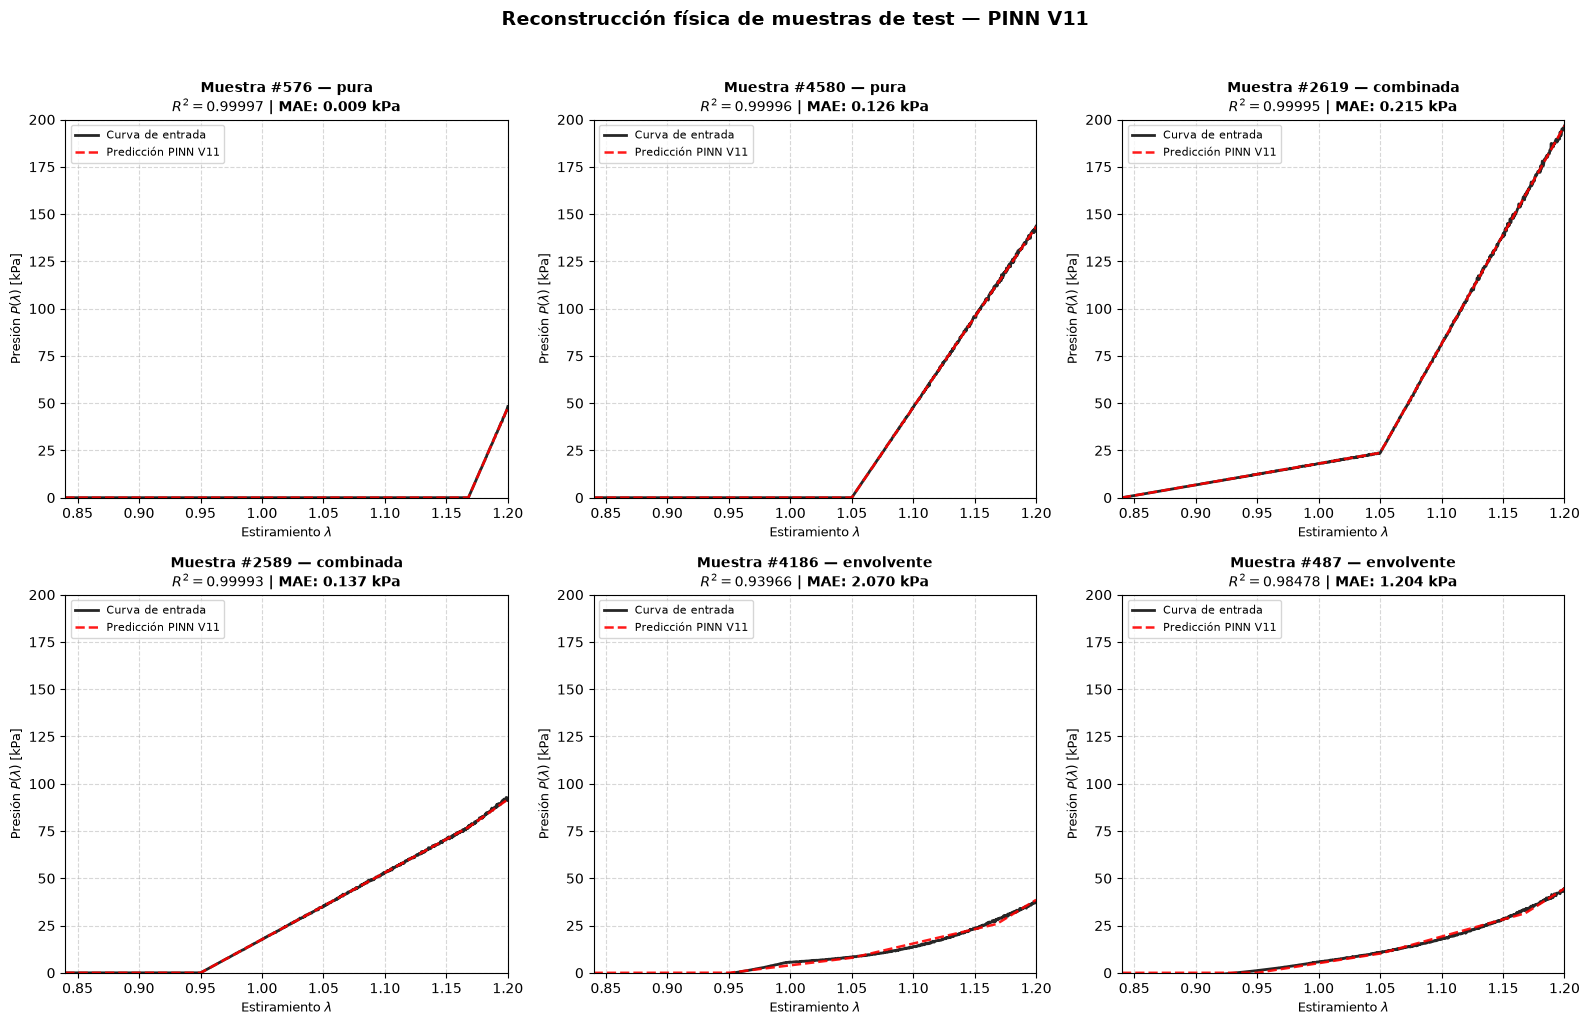

✅ Célula 13 ejecutada. Ventana: λ ∈ [0.84, 1.2] | P ∈ (0, 200) kPa.


In [16]:
# ==============================================================================
# CÉLULA 13: RECONSTRUCCIÓN FÍSICA DE MUESTRAS ALEATORIAS (2 POR FAMILIA)
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

Y_LIM_KPA = (0, 200)

rng_plot = np.random.default_rng(SEED)
indices_muestras = []
for f in sorted(FAMILIAS):
    cand = np.where(EVAL["fam"] == f)[0]
    indices_muestras += [int(i) for i in rng_plot.choice(cand, size=min(2, len(cand)), replace=False)]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, s in zip(axes.flatten(), indices_muestras):
    b_in, b_pred = EVAL["b_in"][s], EVAL["b_rn"][s]
    ax.plot(X_MESH_999, b_in, "k-", linewidth=2.0, label="Curva de entrada", alpha=0.85)
    ax.plot(X_MESH_999, b_pred, "r--", linewidth=1.8, label=f"Predicción PINN {VERSION.upper()}", alpha=0.9)
    ax.set_title(f"Muestra #{s} — {FAMILIAS[int(EVAL['fam'][s])]}\n"
                 f"$R^2 = {r2_score(b_in, b_pred):.5f}$ | MAE: {mean_absolute_error(b_in, b_pred):.3f} kPa",
                 fontweight="bold", fontsize=10)
    ax.set_xlabel(r"Estiramiento $\lambda$", fontsize=9)
    ax.set_ylabel(r"Presión $P(\lambda)$ [kPa]", fontsize=9)
    ax.set_xlim(X_MIN_DOMINIO, X_MAX_DOMINIO)
    ax.set_ylim(*Y_LIM_KPA)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper left", fontsize=8)

plt.suptitle(f"Reconstrucción física de muestras de test — PINN {VERSION.upper()}",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"reconstruccion_ejemplos_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"✅ Célula 13 ejecutada. Ventana: λ ∈ [{X_MIN_DOMINIO}, {X_MAX_DOMINIO}] | P ∈ {Y_LIM_KPA} kPa.")

## Célula 14 — Evaluador universal de Curvas J

📂 Cargando base funcional (malla unificada)...
   • Malla: 999 puntos | Bases (N_BASES): 4
✅ Sistema cargado (v11) | OFFSET_LOG = 14.6474
📖 Cargando curva experimental desde 'Curva_J.xls'...
ℹ️ Piso de envolvente inferior aplicado en 125 de 999 puntos.

🎯 REPORTE COMPARATIVO DE COEFICIENTES (N_BASES = 4)
Coeficiente | Óptimo directo (OLS)   | PINN V11               | Diferencia  
--------------------------------------------------------------------------------
c1          | 0.996263               | 0.997371               | -0.001107   
c2          | 0.000000               | 0.000000               | 0.000000    
c3          | 0.013491               | 0.000000               | 0.013491    
c4          | 0.168392               | 0.147017               | 0.021374    

📊 MÉTRICAS EN [0.84, 1.2]
Métrica      | Óptimo directo (OLS)   | PINN V11              
--------------------------------------------------------------------------------
R2           | 0.999657               | 0.998628         

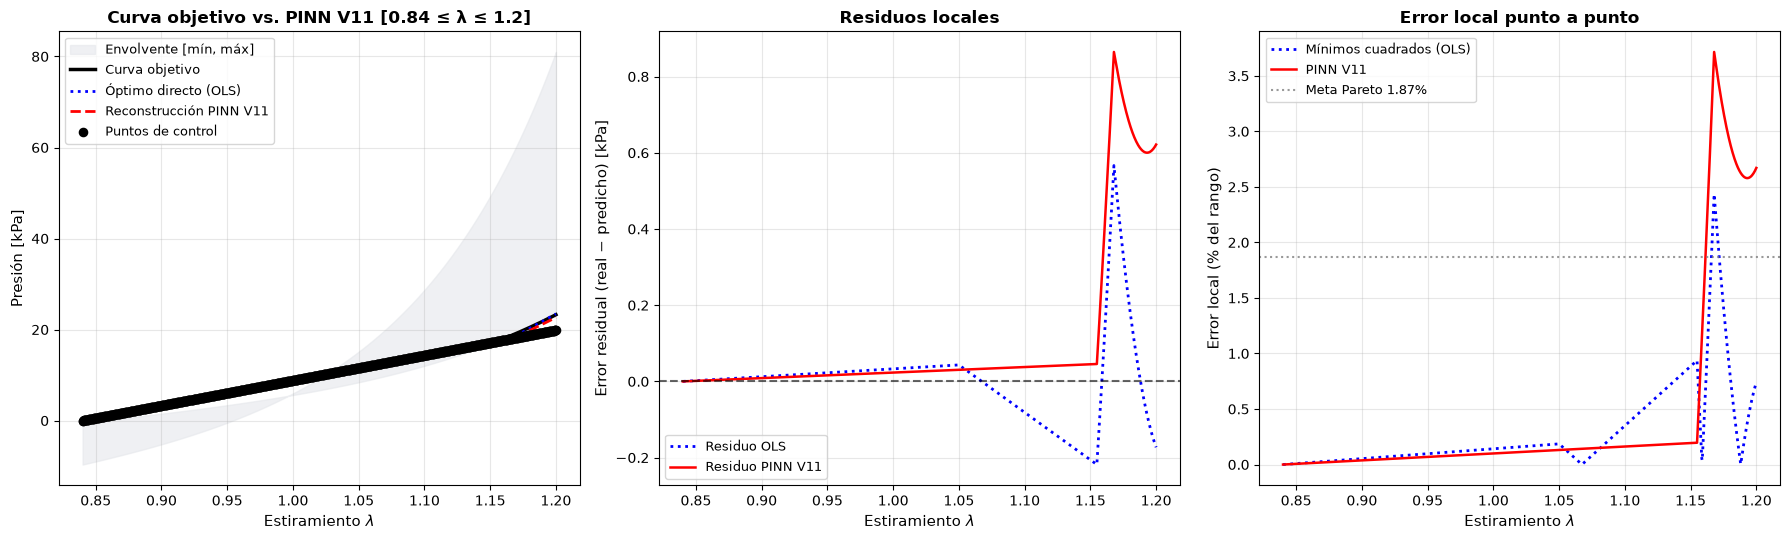

In [18]:
# ==============================================================================
# CÉLULA 14: EVALUADOR UNIVERSAL DE CURVAS J (PINN V11 vs. ÓPTIMO DIRECTO)
# ==============================================================================
"""
Requiere haber ejecutado las Células G y 3 (constantes, fronteras y
safe_log_transform) y haber entrenado/guardado el modelo (Célula 8). Usa los
MISMOS archivos, MAX_COEF, fronteras y OFFSET_LOG que el entrenamiento.
No hace relleno ni recorte silencioso de features: si hay incompatibilidad, falla.
"""
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from scipy.optimize import lsq_linear
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.models import load_model

for _req in ("envolvente_inferior", "envolvente_superior", "safe_log_transform", "MAX_COEF", "ARCHIVO_MODELO"):
    if _req not in globals():
        raise RuntimeError(f"Falta '{_req}': ejecutá primero las Células G y 3.")

# ── 1. CONFIGURACIÓN DEL EVALUADOR ────────────────────────────────────────────────────────────
MODO_ENTRADA = "excel"                 # 'excel' o 'puntos'
TIPO_INTERPOLACION_PUNTOS = "lineal"   # 'lineal' o 'pchip'
ARCHIVO_EXCEL_CURVA_J = "Curva_J.xls"  # (.xls requiere el paquete xlrd)
APLICAR_PISO_ENVOLVENTE = True         # sube la curva a la envolvente inferior (informa cuántos puntos toca)

# Ejemplo de curva por puntos (λ, P[kPa]) DENTRO del dominio [0.84, 1.20]
PUNTOS_USUARIO = [
    (0.84, 0.0),
    (0.95, 5.0),
    (1.05, 20.0),
    (1.15, 55.0),
    (1.20, 80.0),
]


# ── 2. CARGA DE ARCHIVOS ──────────────────────────────────────────────────────────────────────
def cargar_archivos_sistema():
    print("📂 Cargando base funcional (malla unificada)...")
    if not os.path.exists(ARCHIVO_BASES):
        raise FileNotFoundError(f"No se encontró '{ARCHIVO_BASES}'.")
    df_base = pd.read_excel(ARCHIVO_BASES, header=None)
    x_base = df_base.iloc[:, 0].values.astype(np.float64)
    A_base_ev = df_base.iloc[:, 1:].values.astype(np.float64)
    print(f"   • Malla: {len(x_base)} puntos | Bases (N_BASES): {A_base_ev.shape[1]}")

    for f in (ARCHIVO_MODELO, ARCHIVO_SCALERS):
        if not os.path.exists(f):
            raise FileNotFoundError(f"No se encontró '{f}'. Ejecutá la Célula 8 (guarda ambos archivos).")

    modelo = load_model(ARCHIVO_MODELO, compile=False)
    with open(ARCHIVO_SCALERS, "rb") as f:
        meta = pickle.load(f)
    sx_l, sy_l, offset_l = meta["scaler_x"], meta["scaler_y"], meta["offset_log"]

    if modelo.input_shape[-1] != len(x_base) or sx_l.n_features_in_ != len(x_base):
        raise ValueError(f"Incompatibilidad: modelo espera {modelo.input_shape[-1]} features, "
                         f"escalador {sx_l.n_features_in_}, malla de bases {len(x_base)}.")
    if modelo.output_shape[-1] != A_base_ev.shape[1]:
        raise ValueError(f"Incompatibilidad: el modelo predice {modelo.output_shape[-1]} coeficientes "
                         f"y las bases son {A_base_ev.shape[1]}.")
    print(f"✅ Sistema cargado ({meta.get('version', '?')}) | OFFSET_LOG = {offset_l:.4f}")
    return x_base, A_base_ev, modelo, sx_l, sy_l, offset_l


# ── 3. CURVA OBJETIVO ──────────────────────────────────────────────────────────────────────────
def generar_curva_objetivo(x_base):
    if MODO_ENTRADA == "excel":
        print(f"📖 Cargando curva experimental desde '{ARCHIVO_EXCEL_CURVA_J}'...")
        if not os.path.exists(ARCHIVO_EXCEL_CURVA_J):
            raise FileNotFoundError(f"No se encontró '{ARCHIVO_EXCEL_CURVA_J}'.")
        df_curva = pd.read_excel(ARCHIVO_EXCEL_CURVA_J, header=None)
        x_user = df_curva.iloc[:, 0].values.astype(np.float64)
        y_user = df_curva.iloc[:, 1].values.astype(np.float64)
        orden = np.argsort(x_user)
        x_user, y_user = x_user[orden], y_user[orden]
        y_objetivo = np.interp(x_base, x_user, y_user, left=y_user[0], right=y_user[-1])
        puntos_ctrl = list(zip(x_user, y_user))
    else:
        print(f"✏️ Generando curva desde puntos manuales ({TIPO_INTERPOLACION_PUNTOS})...")
        puntos_ordenados = sorted(PUNTOS_USUARIO, key=lambda p: p[0])
        x_ctrl = np.array([p[0] for p in puntos_ordenados], dtype=np.float64)
        y_ctrl = np.array([p[1] for p in puntos_ordenados], dtype=np.float64)
        x_user, y_user = x_ctrl, y_ctrl
        if TIPO_INTERPOLACION_PUNTOS == "pchip":
            y_objetivo = PchipInterpolator(x_ctrl, y_ctrl)(x_base)
        else:
            y_objetivo = np.interp(x_base, x_ctrl, y_ctrl)
        puntos_ctrl = puntos_ordenados

    if x_user.min() > x_base.min() + 1e-9 or x_user.max() < x_base.max() - 1e-9:
        print(f"⚠️ La curva cubre λ ∈ [{x_user.min():.3f}, {x_user.max():.3f}] y el dominio es "
              f"[{x_base.min():.3f}, {x_base.max():.3f}]: los extremos se completan con el valor constante del borde.")

    if APLICAR_PISO_ENVOLVENTE:
        piso = envolvente_inferior(x_base)
        n_mod = int(np.sum(y_objetivo < piso))
        y_objetivo = np.maximum(y_objetivo, piso)
        if n_mod:
            print(f"ℹ️ Piso de envolvente inferior aplicado en {n_mod} de {len(x_base)} puntos.")
    return y_objetivo, puntos_ctrl


# ── 4. AJUSTES: OLS vs PINN ────────────────────────────────────────────────────────────────────
def resolver_ajustes(A_base_ev, b_target, modelo, sx_l, sy_l, offset_l):
    coef_ols = lsq_linear(A_base_ev, b_target, bounds=(COEF_MIN, MAX_COEF)).x
    y_ols = A_base_ev @ coef_ols

    X_log_in = safe_log_transform(b_target, offset=offset_l).reshape(1, -1)   # misma transformación que el entrenamiento
    Yn_pred = modelo.predict(sx_l.transform(X_log_in), verbose=0)
    coef_rn = np.clip(sy_l.inverse_transform(Yn_pred)[0], COEF_MIN, MAX_COEF)
    y_rn = A_base_ev @ coef_rn
    return coef_ols, y_ols, coef_rn, y_rn


# ── 5. MÉTRICAS Y GRÁFICOS ─────────────────────────────────────────────────────────────────────
def calcular_metricas(real, aprox):
    rmse = np.sqrt(mean_squared_error(real, aprox))
    rango = real.max() - real.min()
    return {"R2": r2_score(real, aprox), "RMSE": rmse, "MAE": mean_absolute_error(real, aprox),
            "MaxAE": np.max(np.abs(real - aprox)), "NRMSE": (rmse / rango) * 100.0 if rango > 0 else 0.0}


def graficar_resultados(x, b_real, b_rn, b_ols, pts_ctrl):
    cota_inf_env, cota_sup_env = envolvente_inferior(x), envolvente_superior(x)
    rango_y = b_real.max() - b_real.min()
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

    axes[0].fill_between(x, cota_inf_env, cota_sup_env, color="#e5e7eb", alpha=0.6, label="Envolvente [mín, máx]")
    axes[0].plot(x, b_real, "k-", linewidth=2.5, label="Curva objetivo")
    axes[0].plot(x, b_ols, "b:", linewidth=2.0, label="Óptimo directo (OLS)")
    axes[0].plot(x, b_rn, "r--", linewidth=2.0, label=f"Reconstrucción PINN {VERSION.upper()}")
    pts = [p for p in (pts_ctrl or []) if x.min() <= p[0] <= x.max()]
    if pts:
        px, py = zip(*pts)
        axes[0].scatter(px, py, color="black", zorder=5, s=35, label="Puntos de control")
    axes[0].set_xlabel(r"Estiramiento $\lambda$", fontsize=11)
    axes[0].set_ylabel("Presión [kPa]", fontsize=11)
    axes[0].set_title(f"Curva objetivo vs. PINN {VERSION.upper()} [{X_MIN_DOMINIO} ≤ λ ≤ {X_MAX_DOMINIO}]",
                      fontsize=12, fontweight="bold")
    axes[0].legend(fontsize=9, loc="upper left")
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(x, b_real - b_ols, "b:", linewidth=2.0, label="Residuo OLS")
    axes[1].plot(x, b_real - b_rn, "r-", linewidth=1.8, label=f"Residuo PINN {VERSION.upper()}")
    axes[1].axhline(0, color="black", linestyle="--", alpha=0.6)
    axes[1].set_xlabel(r"Estiramiento $\lambda$", fontsize=11)
    axes[1].set_ylabel("Error residual (real − predicho) [kPa]", fontsize=11)
    axes[1].set_title("Residuos locales", fontsize=12, fontweight="bold")
    axes[1].legend(fontsize=9, loc="lower left")
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(x, np.abs(b_real - b_ols) / rango_y * 100.0, "b:", linewidth=2.0, label="Mínimos cuadrados (OLS)")
    axes[2].plot(x, np.abs(b_real - b_rn) / rango_y * 100.0, "r-", linewidth=1.8, label=f"PINN {VERSION.upper()}")
    axes[2].axhline(1.87, color="gray", linestyle=":", alpha=0.8, label="Meta Pareto 1.87%")
    axes[2].set_xlabel(r"Estiramiento $\lambda$", fontsize=11)
    axes[2].set_ylabel("Error local (% del rango)", fontsize=11)
    axes[2].set_title("Error local punto a punto", fontsize=12, fontweight="bold")
    axes[2].legend(fontsize=9, loc="upper left")
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"evaluacion_inferencia_curva_j_{VERSION}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


# ── 6. PIPELINE ─────────────────────────────────────────────────────────────────────────────────
def ejecutar_pipeline_evaluacion():
    x_base, A_ev, modelo, sx_l, sy_l, offset_l = cargar_archivos_sistema()
    n_bases_ev = A_ev.shape[1]
    y_target, pts_ctrl = generar_curva_objetivo(x_base)
    c_ols, y_ols, c_rn, y_rn = resolver_ajustes(A_ev, y_target, modelo, sx_l, sy_l, offset_l)

    mask_eval = (x_base >= X_MIN_DOMINIO) & (x_base <= X_MAX_DOMINIO)
    x_e, y_t, y_o, y_r = x_base[mask_eval], y_target[mask_eval], y_ols[mask_eval], y_rn[mask_eval]

    col_ols, col_pinn = "Óptimo directo (OLS)", f"PINN {VERSION.upper()}"
    print("\n" + "=" * 80)
    print(f"🎯 REPORTE COMPARATIVO DE COEFICIENTES (N_BASES = {n_bases_ev})")
    print("=" * 80)
    print(f"Coeficiente | {col_ols:<22} | {col_pinn:<22} | {'Diferencia':<12}")
    print("-" * 80)
    for m in range(n_bases_ev):
        print(f"c{m+1:<10} | {c_ols[m]:<22.6f} | {c_rn[m]:<22.6f} | {c_ols[m] - c_rn[m]:<12.6f}")

    m_ols, m_rn = calcular_metricas(y_t, y_o), calcular_metricas(y_t, y_r)
    print("\n" + "=" * 80)
    print(f"📊 MÉTRICAS EN [{X_MIN_DOMINIO}, {X_MAX_DOMINIO}]")
    print("=" * 80)
    print(f"Métrica      | {col_ols:<22} | {col_pinn:<22}")
    print("-" * 80)
    for k in ["R2", "RMSE", "MAE", "MaxAE", "NRMSE"]:
        suf = "%" if k == "NRMSE" else ""
        print(f"{k:<12} | {m_ols[k]:<22.6f}{suf} | {m_rn[k]:<22.6f}{suf}")

    graficar_resultados(x_e, y_t, y_r, y_o, pts_ctrl)


ejecutar_pipeline_evaluacion()

## Célula 15 — Visualización de las bases funcionales

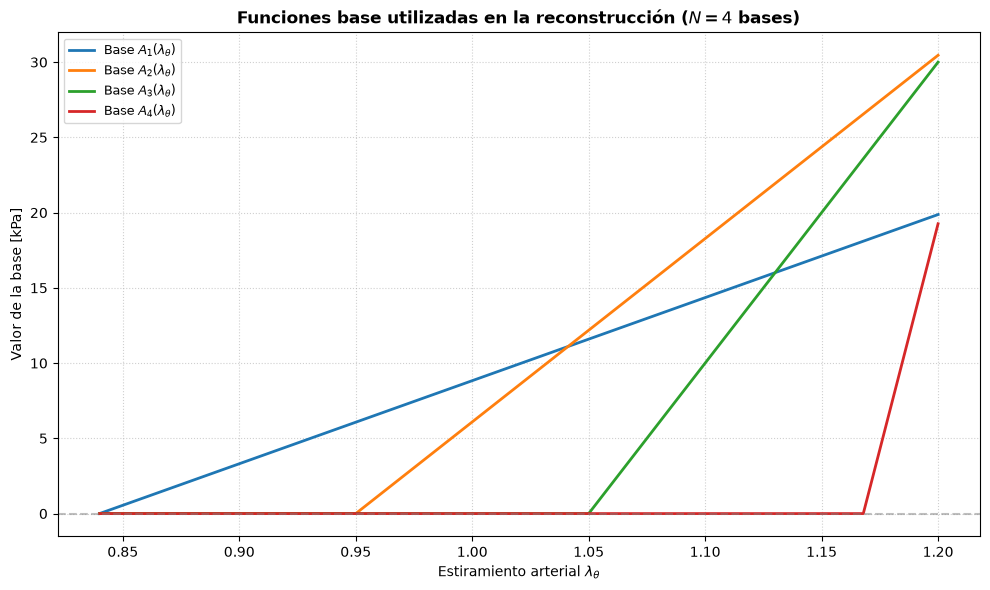

In [17]:
# ==============================================================================
# CÉLULA 15: VISUALIZACIÓN DE LAS BASES FUNCIONALES (A_base)
# ==============================================================================
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
for j in range(A_base.shape[1]):
    plt.plot(X_MESH_999, A_base[:, j], lw=2, label=rf"Base $A_{{{j+1}}}(\lambda_\theta)$")

plt.title(rf"Funciones base utilizadas en la reconstrucción ($N = {A_base.shape[1]}$ bases)",
          fontsize=12, fontweight="bold")
plt.xlabel(r"Estiramiento arterial $\lambda_\theta$", fontsize=10)
plt.ylabel("Valor de la base [kPa]", fontsize=10)
plt.axhline(0, color="gray", linestyle="--", alpha=0.5)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f"bases_funcionales_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()